
Testing activation: relu

Testing activation: swish

Testing activation: tanh

========== ACTIVATION FUNCTION STUDY ==========
Activation  MSE            Res(MHz)       Anti(MHz)      
relu        1.587753e-02   4.7277         4.8991         
swish       1.586013e-02   4.7277         4.7503         
tanh        1.580540e-02   4.7277         5.1373         


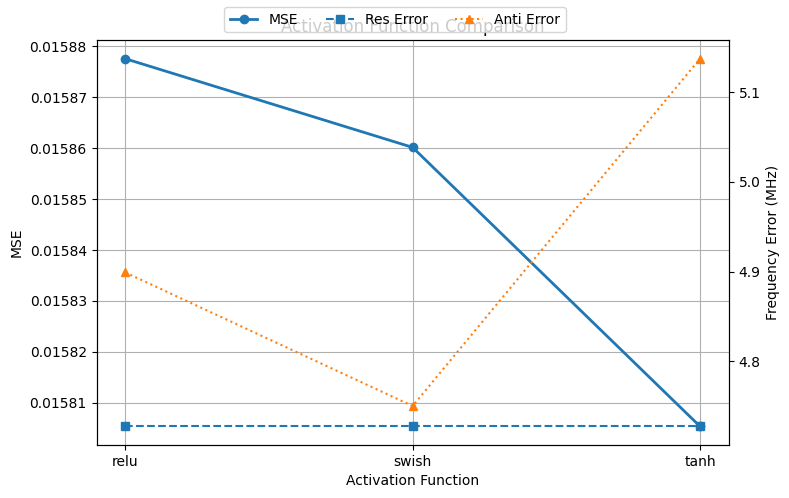

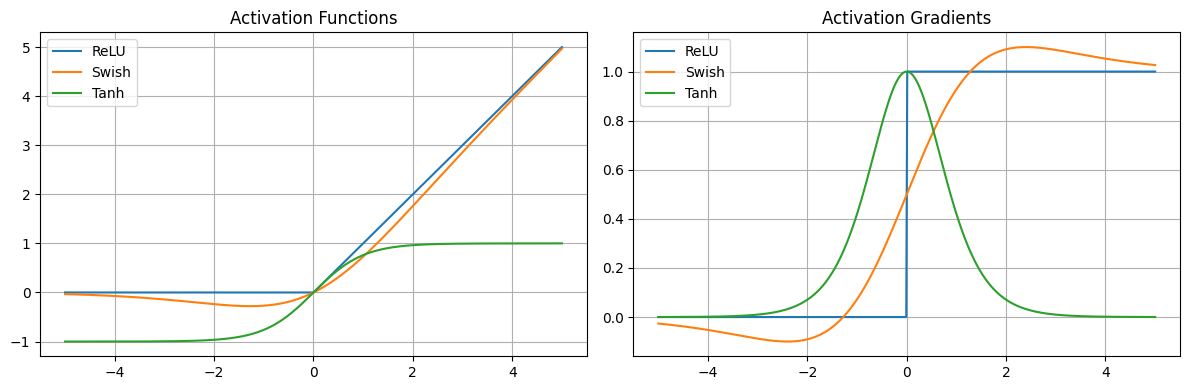

In [ ]:
# =========================================================
# FAST REPRODUCIBLE ACTIVATION FUNCTION STUDY
# STANDARD MBVD + ECP INPUTS
# =========================================================

import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# =========================================================
# REPRODUCIBILITY
# =========================================================
SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

tf.get_logger().setLevel("ERROR")

# =========================================================
# CONSTANTS
# =========================================================
PI = np.pi

N_FREQ = 150
N_SYNTH = 80

R0_FIXED = 0.25
RS_FIXED = 0.12

# =========================================================
# REAL RESONATORS
# =========================================================
real_resonators = [

{"C0":7.95e-13,"fr":2468e6,"fa":2577e6,"Qs":887},
{"C0":5.989e-13,"fr":2466e6,"fa":2576e6,"Qs":1034},
{"C0":3.981e-13,"fr":2468e6,"fa":2578e6,"Qs":1994},
{"C0":1.857e-12,"fr":2461e6,"fa":2565e6,"Qs":935},
{"C0":1.39e-12,"fr":2488e6,"fa":2597e6,"Qs":804},
{"C0":1.65e-12,"fr":2324e6,"fa":2435e6,"Qs":1038},
{"C0":1.70e-12,"fr":2324e6,"fa":2427e6,"Qs":911},
{"C0":2.60e-12,"fr":1298e6,"fa":1362e6,"Qs":1470},
{"C0":2.03e-12,"fr":1487e6,"fa":1564e6,"Qs":1249},
{"C0":2.36e-12,"fr":1477e6,"fa":1553e6,"Qs":904},
{"C0":1.096e-12,"fr":1722e6,"fa":1806e6,"Qs":2688},
{"C0":3.01e-12,"fr":1443e6,"fa":1512e6,"Qs":1353},
{"C0":3.244e-12,"fr":1269e6,"fa":1329e6,"Qs":1643},
{"C0":1.242e-12,"fr":2847e6,"fa":2958e6,"Qs":906},
{"C0":1.592e-12,"fr":2467e6,"fa":2576e6,"Qs":832},
{"C0":1.90e-12,"fr":2314e6,"fa":2419e6,"Qs":1181},
{"C0":2.132e-12,"fr":2074e6,"fa":2172e6,"Qs":892},
{"C0":2.47e-12,"fr":1719e6,"fa":1800e6,"Qs":974},
{"C0":1.07e-12,"fr":1723e6,"fa":1807e6,"Qs":2291},
{"C0":2.02e-12,"fr":1485e6,"fa":1559e6,"Qs":1089},
{"C0":1.57e-12,"fr":2467e6,"fa":2579e6,"Qs":1095},
{"C0":1.58e-12,"fr":2092e6,"fa":2194e6,"Qs":857}
]

# =========================================================
# SYNTHETIC DATA
# =========================================================
def generate_synthetic_resonators(n):

    resonators=[]

    while len(resonators)<n:

        fr=np.random.uniform(1.2e9,2.8e9)

        k2=np.random.uniform(0.075,0.10)

        C0=np.random.uniform(0.5e-12,3e-12)

        Qs=np.random.uniform(600,3000)

        fa=(2*fr)/(1+np.sqrt(1-16*k2/(PI**2)))

        resonators.append({

            "C0":C0,
            "fr":fr,
            "fa":fa,
            "Qs":Qs

        })

    return resonators

# =========================================================
# STANDARD MBVD PARAMETERS
# =========================================================
def compute_mbvd_parameters(r):

    fr=r["fr"]

    fa=r["fa"]

    C0=r["C0"]

    Qs=r["Qs"]

    # =====================================================
    # MOTIONAL PARAMETERS
    # =====================================================
    Cm=C0*((fa/fr)**2-1)

    Lm=1/((2*PI*fr)**2 * Cm)

    wr=2*PI*fr

    Rm=wr*Lm/Qs

    # =====================================================
    # STANDARD MBVD PARASITICS
    # =====================================================
    R0=R0_FIXED

    Rs=RS_FIXED

    return Rm,Lm,Cm,C0,R0,Rs

# =========================================================
# STANDARD MBVD RESPONSE
# =========================================================
def compute_Y11(r):

    fr=r["fr"]

    fa=r["fa"]

    Rm,Lm,Cm,C0,R0,Rs=compute_mbvd_parameters(r)

    f=np.linspace(fr*0.93,fa*1.07,N_FREQ)

    w=2*PI*f

    # =====================================================
    # STATIC BRANCH
    # =====================================================
    Zs=R0 + 1/(1j*w*C0)

    # =====================================================
    # MOTIONAL BRANCH
    # =====================================================
    Zm=Rm + 1/(1j*w*Cm) + 1j*w*Lm

    # =====================================================
    # PARALLEL NETWORK
    # =====================================================
    Zp=1/(1/Zs + 1/Zm)

    # =====================================================
    # TOTAL IMPEDANCE
    # =====================================================
    Ztotal=Rs + Zp

    Y11=np.abs(1/Ztotal)

    return Y11,f

# =========================================================
# PRECOMPUTE CURVES
# =========================================================
synthetic_resonators=generate_synthetic_resonators(N_SYNTH)

all_resonators=real_resonators + synthetic_resonators

precomputed_data={}

for r in all_resonators:

    Y,f=compute_Y11(r)

    precomputed_data[id(r)]=(Y,f)

# =========================================================
# FREQUENCY EXTRACTION
# =========================================================
def extract_frequencies(Y,f):

    fr=f[np.argmax(Y)]

    fa=f[np.argmin(Y)]

    return fr,fa

# =========================================================
# ACTIVATION TEST
# =========================================================
activations=["relu","swish","tanh"]

results={}

for act in activations:

    print("\nTesting activation:",act)

    mse_list=[]

    res_error=[]

    anti_error=[]

    for i in range(len(real_resonators)):

        test_res=real_resonators[i]

        train_real=(

            real_resonators[:i] +

            real_resonators[i+1:]

        )

        train_res=train_real + synthetic_resonators

        X_train=[]

        Y_train=[]

        # =================================================
        # TRAINING DATA
        # =================================================
        for r in train_res:

            Rm,Lm,Cm,C0,R0,Rs=compute_mbvd_parameters(r)

            X_train.append([

                Rm,
                Lm,
                Cm,
                C0,
                R0,
                Rs

            ])

            Y_train.append(

                precomputed_data[id(r)][0]

            )

        X_train=np.array(X_train,np.float32)

        Y_train=np.array(Y_train,np.float32)

        # =================================================
        # SAFE NORMALIZATION
        # =================================================
        Xm=X_train.mean(0)

        Xs=X_train.std(0)

        Ym=Y_train.mean(0)

        Ys=Y_train.std(0)

        Xs=np.where(Xs<1e-12,1.0,Xs)

        Ys=np.where(Ys<1e-12,1.0,Ys)

        Xn=(X_train-Xm)/Xs

        Yn=(Y_train-Ym)/Ys

        # =================================================
        # MODEL
        # =================================================
        model=tf.keras.Sequential([

        tf.keras.layers.Input((6,)),

        tf.keras.layers.Dense(
            96,
            activation=act
        ),

        tf.keras.layers.Dense(
            96,
            activation=act
        ),

        tf.keras.layers.Dense(
            128,
            activation=act
        ),

        tf.keras.layers.Dense(
            N_FREQ,
            activation="softplus"
        )

        ])

        model.compile(

            optimizer=tf.keras.optimizers.Adam(5e-4),

            loss="mse"

        )

        earlystop=tf.keras.callbacks.EarlyStopping(

            monitor="loss",

            patience=8,

            restore_best_weights=True

        )

        model.fit(

            Xn,
            Yn,

            epochs=60,

            batch_size=16,

            shuffle=False,

            verbose=0,

            callbacks=[earlystop]

        )

        # =================================================
        # TEST SAMPLE
        # =================================================
        Rm,Lm,Cm,C0,R0,Rs=compute_mbvd_parameters(test_res)

        Xt=np.array([[

            Rm,
            Lm,
            Cm,
            C0,
            R0,
            Rs

        ]],dtype=np.float32)

        Xt=(Xt-Xm)/Xs

        # =================================================
        # PREDICTION
        # =================================================
        Y_pred=model.predict(

            Xt,
            verbose=0

        )[0]

        Y_pred=Y_pred*Ys + Ym

        Y_true,f=precomputed_data[id(test_res)]

        # =================================================
        # METRICS
        # =================================================
        mse_list.append(

            np.mean((Y_true-Y_pred)**2)

        )

        fr_true,fa_true=extract_frequencies(Y_true,f)

        fr_pred,fa_pred=extract_frequencies(Y_pred,f)

        res_error.append(

            abs(fr_true-fr_pred)/1e6

        )

        anti_error.append(

            abs(fa_true-fa_pred)/1e6

        )

    results[act]={

        "MSE":np.mean(mse_list),

        "ResError":np.mean(res_error),

        "AntiError":np.mean(anti_error)

    }

# =========================================================
# PRINT RESULTS
# =========================================================
print("\n========== ACTIVATION FUNCTION STUDY ==========")

print(f"{'Activation':<12}{'MSE':<15}{'Res(MHz)':<15}{'Anti(MHz)':<15}")

for k,v in results.items():

    print(f"{k:<12}{v['MSE']:<15.6e}{v['ResError']:<15.4f}{v['AntiError']:<15.4f}")

# =========================================================
# PERFORMANCE PLOT
# =========================================================
names=list(results.keys())

mse_vals=[results[a]["MSE"] for a in names]

res_vals=[results[a]["ResError"] for a in names]

anti_vals=[results[a]["AntiError"] for a in names]

fig, ax1 = plt.subplots(figsize=(8,5))

ax1.plot(

    names,

    mse_vals,

    marker="o",

    linewidth=2

)

ax1.set_ylabel("MSE")

ax1.set_xlabel("Activation Function")

ax1.grid(True)

ax2=ax1.twinx()

ax2.plot(

    names,

    res_vals,

    marker="s",

    linestyle="--"

)

ax2.plot(

    names,

    anti_vals,

    marker="^",

    linestyle=":"

)

ax2.set_ylabel("Frequency Error (MHz)")

fig.legend(

    ["MSE","Res Error","Anti Error"],

    loc="upper center",

    ncol=3

)

plt.title("Activation Function Comparison")

plt.tight_layout()

plt.show()

# =========================================================
# ACTIVATION FUNCTIONS + GRADIENTS
# =========================================================
x=np.linspace(-5,5,500)

relu=np.maximum(0,x)

tanh=np.tanh(x)

swish=x*(1/(1+np.exp(-x)))

relu_grad=np.where(x>0,1,0)

tanh_grad=1-np.tanh(x)**2

sigmoid=1/(1+np.exp(-x))

swish_grad=sigmoid + x*sigmoid*(1-sigmoid)

fig,axes=plt.subplots(1,2,figsize=(12,4))

# =========================================================
# ACTIVATIONS
# =========================================================
axes[0].plot(x,relu,label="ReLU")

axes[0].plot(x,swish,label="Swish")

axes[0].plot(x,tanh,label="Tanh")

axes[0].set_title("Activation Functions")

axes[0].legend()

axes[0].grid(True)

# =========================================================
# GRADIENTS
# =========================================================
axes[1].plot(x,relu_grad,label="ReLU")

axes[1].plot(x,swish_grad,label="Swish")

axes[1].plot(x,tanh_grad,label="Tanh")

axes[1].set_title("Activation Gradients")

axes[1].legend()

axes[1].grid(True)

plt.tight_layout()

plt.show()


Testing activation: relu

Testing activation: swish

Testing activation: tanh

========== ACTIVATION FUNCTION STUDY ==========
Activation  Curve MSE         Res Error(MHz)    Anti Error(MHz)   
relu        1.626218e-02      2.5749            1.4570            
swish       1.628354e-02      2.4177            1.4570            
tanh        1.656083e-02      2.4177            1.4570            


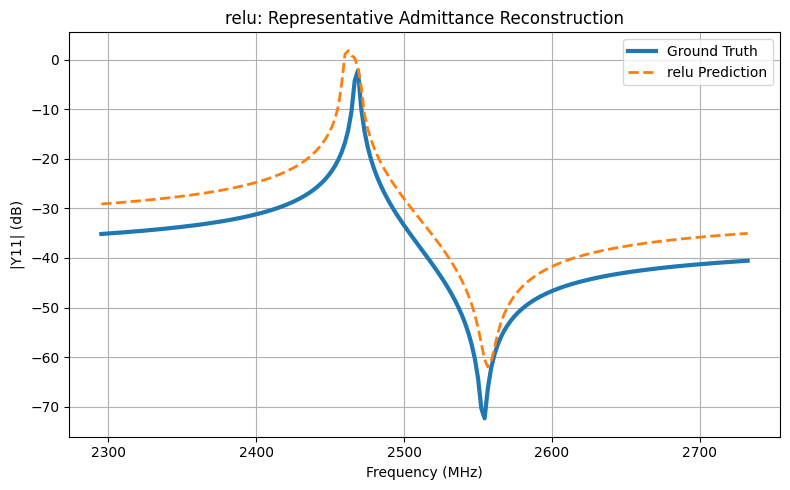

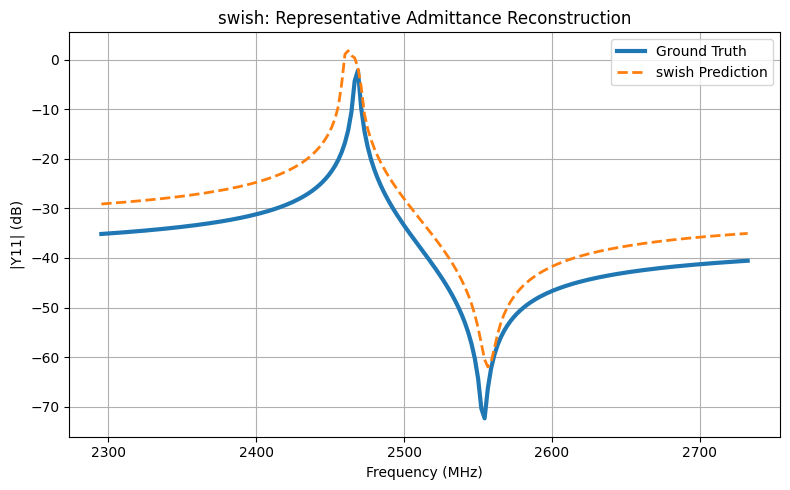

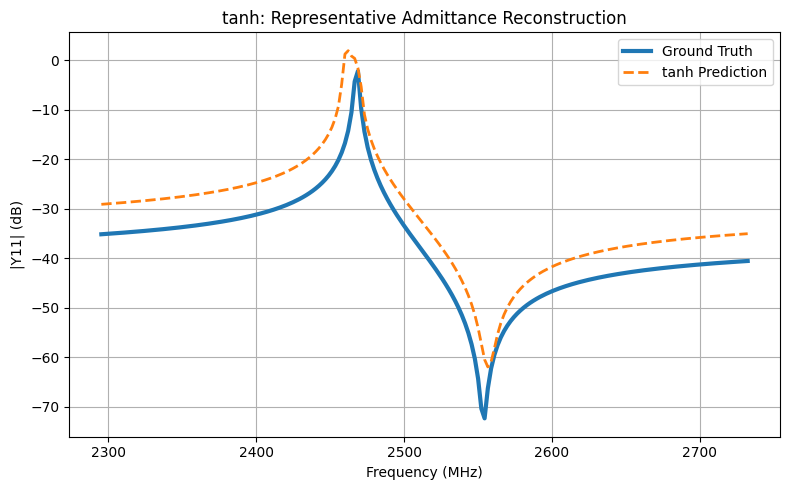

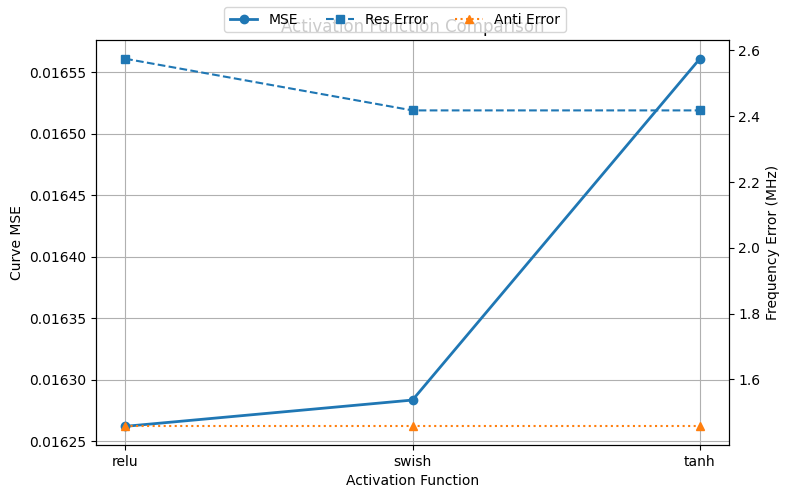

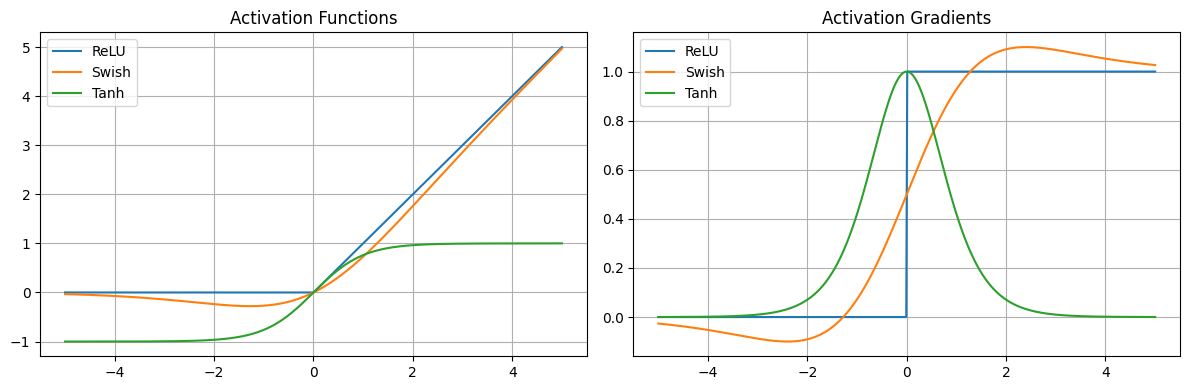

In [ ]:
# =========================================================
# REPRODUCIBLE ACTIVATION FUNCTION STUDY
# PHYSICS-GUIDED MBVD FORMULATION
# =========================================================

import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# =========================================================
# FULL REPRODUCIBILITY
# =========================================================
SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

tf.get_logger().setLevel("ERROR")

# =========================================================
# CONSTANTS
# =========================================================
PI = np.pi

N_FREQ = 200

N_SYNTH = 120

# =========================================================
# REAL RESONATORS
# =========================================================
# INPUT DESCRIPTORS:
# (Cs, fr, Qs, Qp, R0, k2)
# =========================================================
real_resonators = [

{"Cs":7.95e-13,"fr":2468e6,"Qs":887,"Qp":3770,"R0":0.257,"k2":0.080},
{"Cs":5.989e-13,"fr":2466e6,"Qs":1034,"Qp":1379,"R0":0.257,"k2":0.080},
{"Cs":3.981e-13,"fr":2468e6,"Qs":1994,"Qp":1052,"R0":0.257,"k2":0.085},
{"Cs":1.857e-12,"fr":2461e6,"Qs":935,"Qp":2513,"R0":0.257,"k2":0.081},
{"Cs":1.39e-12,"fr":2488e6,"Qs":804,"Qp":1732,"R0":0.257,"k2":0.084},
{"Cs":1.65e-12,"fr":2324e6,"Qs":1038,"Qp":1112,"R0":0.257,"k2":0.091},
{"Cs":1.70e-12,"fr":2324e6,"Qs":911,"Qp":1683,"R0":0.257,"k2":0.0855},
{"Cs":2.60e-12,"fr":1298e6,"Qs":1470,"Qp":2580,"R0":0.257,"k2":0.093},
{"Cs":2.03e-12,"fr":1487e6,"Qs":1249,"Qp":1966,"R0":0.257,"k2":0.097},
{"Cs":2.36e-12,"fr":1477e6,"Qs":904,"Qp":1153,"R0":0.257,"k2":0.096},
{"Cs":1.096e-12,"fr":1722e6,"Qs":2688,"Qp":3530,"R0":0.257,"k2":0.092},
{"Cs":3.01e-12,"fr":1443e6,"Qs":1353,"Qp":1585,"R0":0.257,"k2":0.091},
{"Cs":3.244e-12,"fr":1269e6,"Qs":1643,"Qp":1645,"R0":0.257,"k2":0.0891},
{"Cs":1.242e-12,"fr":2847e6,"Qs":906,"Qp":2170,"R0":0.257,"k2":0.0747},
{"Cs":1.592e-12,"fr":2467e6,"Qs":832,"Qp":2911,"R0":0.257,"k2":0.0846},
{"Cs":1.90e-12,"fr":2314e6,"Qs":1181,"Qp":2603,"R0":0.257,"k2":0.086},
{"Cs":2.132e-12,"fr":2074e6,"Qs":892,"Qp":3792,"R0":0.257,"k2":0.089},
{"Cs":2.47e-12,"fr":1719e6,"Qs":974,"Qp":4742,"R0":0.257,"k2":0.090},
{"Cs":1.07e-12,"fr":1723e6,"Qs":2291,"Qp":1939,"R0":0.257,"k2":0.093},
{"Cs":2.02e-12,"fr":1485e6,"Qs":1089,"Qp":6853,"R0":0.257,"k2":0.094},
{"Cs":1.57e-12,"fr":2467e6,"Qs":1095,"Qp":1312,"R0":0.257,"k2":0.0868},
{"Cs":1.58e-12,"fr":2092e6,"Qs":857,"Qp":1712,"R0":0.257,"k2":0.092}

]

# =========================================================
# SYNTHETIC DATA
# =========================================================
def generate_synthetic_resonators(n):

    resonators=[]

    while len(resonators)<n:

        resonators.append({

            "Cs": np.random.uniform(0.5e-12,3.5e-12),

            "fr": np.random.uniform(1.2e9,2.9e9),

            "Qs": np.random.uniform(700,3000),

            "Qp": np.random.uniform(1000,7000),

            "R0": 0.257,

            "k2": np.random.uniform(0.074,0.10)

        })

    return resonators

# =========================================================
# PHYSICS-GUIDED MBVD PARAMETERS
# =========================================================
def compute_mbvd_parameters(r):

    Cs=r["Cs"]

    fr=r["fr"]

    Qs=r["Qs"]

    Qp=r["Qp"]

    R0=r["R0"]

    k2=r["k2"]

    # =====================================================
    # ANTI-RESONANCE FREQUENCY
    # =====================================================
    fa=(

        2*fr

        /

        (

            1 +

            np.sqrt(

                1 - (16*k2)/(PI**2)

            )

        )

    )

    wr=2*PI*fr

    wa=2*PI*fa

    # =====================================================
    # MOTIONAL CAPACITANCE
    # =====================================================
    Cm=Cs*((fa/fr)**2 -1)

    # =====================================================
    # MOTIONAL INDUCTANCE
    # =====================================================
    Lm=1/((wr**2)*Cm)

    # =====================================================
    # MOTIONAL RESISTANCE
    # =====================================================
    Rm=wr*(Lm/Qs) - R0

    # =====================================================
    # STATIC BRANCH LOSS
    # =====================================================
    Rs=wa*(Lm/Qp) - Rm

    # =====================================================
    # SAFETY
    # =====================================================
    Rm=np.maximum(Rm,1e-6)

    Rs=np.maximum(Rs,1e-6)

    Cm=np.maximum(Cm,1e-18)

    Lm=np.maximum(Lm,1e-18)

    return Rm,Lm,Cm,Cs,R0,Rs,fa

# =========================================================
# PHYSICS-GUIDED MBVD RESPONSE
# =========================================================
def compute_Y11(r):

    fr=r["fr"]

    Rm,Lm,Cm,Cs,R0,Rs,fa=compute_mbvd_parameters(r)

    f=np.linspace(

        fr*0.93,

        fa*1.07,

        N_FREQ

    )

    w=2*PI*f

    # =====================================================
    # STATIC BRANCH
    # =====================================================
    Zs=R0 + 1/(1j*w*Cs)

    # =====================================================
    # MOTIONAL BRANCH
    # =====================================================
    Zm=Rm + 1/(1j*w*Cm) + 1j*w*Lm

    # =====================================================
    # PARALLEL NETWORK
    # =====================================================
    Zp=1/(1/Zs + 1/Zm)

    # =====================================================
    # TOTAL IMPEDANCE
    # =====================================================
    Ztotal=Rs + Zp

    Y11=np.abs(1/Ztotal)

    return Y11,f

# =========================================================
# PRECOMPUTE CURVES
# =========================================================
synthetic_resonators=generate_synthetic_resonators(N_SYNTH)

all_resonators=real_resonators + synthetic_resonators

precomputed_data={}

for r in all_resonators:

    Y,f=compute_Y11(r)

    precomputed_data[id(r)]=(Y,f)

# =========================================================
# FREQUENCY EXTRACTION
# =========================================================
def extract_frequencies(Y,f):

    fr=f[np.argmax(Y)]

    fa=f[np.argmin(Y)]

    return fr,fa

# =========================================================
# ACTIVATION FUNCTIONS
# =========================================================
activations=["relu","swish","tanh"]

results={}

example_predictions={}

# =========================================================
# MAIN EXPERIMENT LOOP
# =========================================================
for act in activations:

    print("\nTesting activation:",act)

    mse_list=[]

    res_error=[]

    anti_error=[]

    representative_example=None

    # =====================================================
    # LOOCV
    # =====================================================
    for i in range(len(real_resonators)):

        test_res=real_resonators[i]

        train_real=(

            real_resonators[:i] +

            real_resonators[i+1:]

        )

        train_res=train_real + synthetic_resonators

        X_train=[]

        Y_train=[]

        # =================================================
        # TRAINING DATA
        # =================================================
        for r in train_res:

            Rm,Lm,Cm,Cs,R0,Rs,fa=compute_mbvd_parameters(r)

            X_train.append([

                Rm,
                Lm,
                Cm,
                Cs,
                R0,
                Rs

            ])

            Y_train.append(

                precomputed_data[id(r)][0]

            )

        X_train=np.array(X_train,np.float32)

        Y_train=np.array(Y_train,np.float32)

        # =================================================
        # SAFE NORMALIZATION
        # =================================================
        Xm=X_train.mean(0)

        Xs=X_train.std(0)

        Ym=Y_train.mean(0)

        Ys=Y_train.std(0)

        Xs=np.where(Xs<1e-12,1.0,Xs)

        Ys=np.where(Ys<1e-12,1.0,Ys)

        Xn=(X_train-Xm)/Xs

        Yn=(Y_train-Ym)/Ys

        # =================================================
        # FINAL STANDARDIZED MLP
        # =================================================
        model=tf.keras.Sequential([

        tf.keras.layers.Input((6,)),

        tf.keras.layers.Dense(
            96,
            activation=act
        ),

        tf.keras.layers.Dense(
            96,
            activation=act
        ),

        tf.keras.layers.Dense(
            128,
            activation=act
        ),

        tf.keras.layers.Dense(
            N_FREQ,
            activation="softplus"
        )

        ])

        # =================================================
        # COMPILE
        # =================================================
        model.compile(

            optimizer=tf.keras.optimizers.Adam(
                learning_rate=1e-3
            ),

            loss="mse"

        )

        # =================================================
        # EARLY STOPPING
        # =================================================
        earlystop=tf.keras.callbacks.EarlyStopping(

            monitor="loss",

            patience=15,

            restore_best_weights=True

        )

        # =================================================
        # TRAINING
        # =================================================
        model.fit(

            Xn,
            Yn,

            epochs=120,

            batch_size=16,

            shuffle=True,

            verbose=0,

            callbacks=[earlystop]

        )

        # =================================================
        # TEST SAMPLE
        # =================================================
        Rm,Lm,Cm,Cs,R0,Rs,fa=compute_mbvd_parameters(test_res)

        Xt=np.array([[

            Rm,
            Lm,
            Cm,
            Cs,
            R0,
            Rs

        ]],dtype=np.float32)

        Xt=(Xt-Xm)/Xs

        # =================================================
        # PREDICTION
        # =================================================
        Y_pred=model.predict(

            Xt,
            verbose=0

        )[0]

        Y_pred=Y_pred*Ys + Ym

        Y_true,f=precomputed_data[id(test_res)]

        # =================================================
        # METRICS
        # =================================================
        mse_list.append(

            np.mean((Y_true-Y_pred)**2)

        )

        fr_true,fa_true=extract_frequencies(Y_true,f)

        fr_pred,fa_pred=extract_frequencies(Y_pred,f)

        res_error.append(

            abs(fr_true-fr_pred)/1e6

        )

        anti_error.append(

            abs(fa_true-fa_pred)/1e6

        )

        # =================================================
        # REPRESENTATIVE EXAMPLE
        # =================================================
        if i==0:

            representative_example={

                "f":f,

                "Y_true":Y_true,

                "Y_pred":Y_pred

            }

    # =====================================================
    # STORE RESULTS
    # =====================================================
    results[act]={

        "MSE":np.mean(mse_list),

        "ResError":np.mean(res_error),

        "AntiError":np.mean(anti_error)

    }

    example_predictions[act]=representative_example

# =========================================================
# PRINT RESULTS
# =========================================================
print("\n========== ACTIVATION FUNCTION STUDY ==========")

print(f"{'Activation':<12}"
      f"{'Curve MSE':<18}"
      f"{'Res Error(MHz)':<18}"
      f"{'Anti Error(MHz)':<18}")

for k,v in results.items():

    print(f"{k:<12}"
          f"{v['MSE']:<18.6e}"
          f"{v['ResError']:<18.4f}"
          f"{v['AntiError']:<18.4f}")

# =========================================================
# REPRESENTATIVE CURVE PLOTS
# =========================================================
for act, ex in example_predictions.items():

    plt.figure(figsize=(8,5))

    plt.plot(

        ex["f"]/1e6,

        20*np.log10(ex["Y_true"] + 1e-15),

        linewidth=3,

        label="Ground Truth"

    )

    plt.plot(

        ex["f"]/1e6,

        20*np.log10(ex["Y_pred"] + 1e-15),

        "--",

        linewidth=2,

        label=f"{act} Prediction"

    )

    plt.xlabel("Frequency (MHz)")

    plt.ylabel("|Y11| (dB)")

    plt.title(

        f"{act}: Representative Admittance Reconstruction"

    )

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()

# =========================================================
# PERFORMANCE PLOT
# =========================================================
names=list(results.keys())

mse_vals=[results[a]["MSE"] for a in names]

res_vals=[results[a]["ResError"] for a in names]

anti_vals=[results[a]["AntiError"] for a in names]

fig, ax1 = plt.subplots(figsize=(8,5))

# =========================================================
# MSE
# =========================================================
ax1.plot(

    names,

    mse_vals,

    marker="o",

    linewidth=2

)

ax1.set_ylabel("Curve MSE")

ax1.set_xlabel("Activation Function")

ax1.grid(True)

# =========================================================
# FREQUENCY ERRORS
# =========================================================
ax2=ax1.twinx()

ax2.plot(

    names,

    res_vals,

    marker="s",

    linestyle="--"

)

ax2.plot(

    names,

    anti_vals,

    marker="^",

    linestyle=":"

)

ax2.set_ylabel("Frequency Error (MHz)")

fig.legend(

    ["MSE","Res Error","Anti Error"],

    loc="upper center",

    ncol=3

)

plt.title("Activation Function Comparison")

plt.tight_layout()

plt.show()

# =========================================================
# ACTIVATION FUNCTIONS
# =========================================================
x=np.linspace(-5,5,500)

relu=np.maximum(0,x)

tanh=np.tanh(x)

swish=x*(1/(1+np.exp(-x)))

relu_grad=np.where(x>0,1,0)

tanh_grad=1-np.tanh(x)**2

sigmoid=1/(1+np.exp(-x))

swish_grad=sigmoid + x*sigmoid*(1-sigmoid)

fig,axes=plt.subplots(1,2,figsize=(12,4))

# =========================================================
# ACTIVATIONS
# =========================================================
axes[0].plot(x,relu,label="ReLU")

axes[0].plot(x,swish,label="Swish")

axes[0].plot(x,tanh,label="Tanh")

axes[0].set_title("Activation Functions")

axes[0].legend()

axes[0].grid(True)

# =========================================================
# GRADIENTS
# =========================================================
axes[1].plot(x,relu_grad,label="ReLU")

axes[1].plot(x,swish_grad,label="Swish")

axes[1].plot(x,tanh_grad,label="Tanh")

axes[1].set_title("Activation Gradients")

axes[1].legend()

axes[1].grid(True)

plt.tight_layout()

plt.show()